# Phase 3: Data Mining

**Dataset:** Preprocessed Student Performance Dataset (750 records, 23 columns)  
**Class label:** `final_grade` (A, B, C, D, F)

In this phase, we apply data mining techniques to the preprocessed Student Performance dataset from Phase 2. We use Decision Tree Classification to predict students' final grades using two attribute selection measures (Gini and Entropy) and three different data partitions (70/30, 80/20, and 90/10). We will also apply K-Means Clustering to group students based on similar characteristics. The results will be evaluated, compared, and visualized to understand the performance of each technique and identify useful patterns in the data.

# 1. Classification

## 1.1 Decision Tree Classification

In [94]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn import tree
import matplotlib.pyplot as plt

In [95]:
# Load the preprocessed student dataset
df = pd.read_csv("Preprocessed_dataset.csv")
print(df.head())

# Use final_grade as the target
y = df['final_grade']

# Remove the ID, target, and columns we do not need
X = df.drop(columns=[
    'student_id',
    'final_grade',
    'final_grade_transformed',
    'final_score',
    'gender',
    'internet_access',
    'parent_education',
    'part_time_job',
    'extracurricular'
])

# Convert the remaining categorical columns into numbers
X = pd.get_dummies(X)

fn = X.columns.tolist()

print("Features:", fn)
print("Dataset shape:", X.shape)

   student_id  age  gender  study_hours  attendance_rate  assignment_score  \
0           1   24  Female         3.06         0.248374          0.675286   
1           2   21    Male         3.26         0.133567          0.572774   
2           3   22  Female         4.63         0.418459          0.789989   
3           4   24  Female         3.42         0.790395          0.384559   
4           5   20    Male         2.15         0.582291          0.518471   

   midterm_score  final_score internet_access parent_education  ...  \
0       0.511979     0.728753              No              PhD  ...   
1       0.054015     0.750814             Yes      High School  ...   
2       0.543343     0.380367              No         Bachelor  ...   
3       0.760418     0.696328             Yes      High School  ...   
4       0.565558     0.620669             Yes           Master  ...   

   extracurricular final_grade  discretized_age discretized_study_hours  \
0              Yes           

In [96]:

# Try three different training and testing splits
partitions = {
    "70/30": 0.3,
    "80/20": 0.2,
    "90/10": 0.1
}

In [97]:

# Compare Gini and Entropy to see which one works better
criteria = ['gini', 'entropy']

results = []
result_matrices = []
best_accuracy = -1


In [98]:

# Train and test the Decision Tree using different splits
for partition, test_size in partitions.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=1
    )

    # Try Gini and Entropy for each split
    for criterion in criteria:

        clf = DecisionTreeClassifier(
            criterion=criterion,
            random_state=1
        )

        clf = clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        # Check how well the model performs
        accuracy = metrics.accuracy_score(y_test, y_pred)

        train_accuracy = metrics.accuracy_score(
            y_train, clf.predict(X_train)
        )

        f1 = metrics.f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )

        cm = confusion_matrix(
            y_test, y_pred,
            labels=clf.classes_
        )

        print("\nPartition:", partition)
        print("Criterion:", criterion)
        print("Training Accuracy:", train_accuracy)
        print("Testing Accuracy:", accuracy)
        print("F1-score:", f1)
        print("Confusion Matrix:")
        print(cm)

        # Save the results to compare them later
        results.append({
            "Partition": partition,
            "Criterion": criterion,
            "Training Accuracy": train_accuracy,
            "Accuracy": accuracy,
            "F1-score": f1
        })

        # Save each confusion matrix for the plots
        result_matrices.append({
            "Partition": partition,
            "Criterion": criterion,
            "Matrix": cm,
            "Labels": clf.classes_
        })

        # Keep the model with the highest testing accuracy
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_clf = clf
            best_partition = partition
            best_criterion = criterion



Partition: 70/30
Criterion: gini
Training Accuracy: 1.0
Testing Accuracy: 0.2088888888888889
F1-score: 0.20653677270543852
Confusion Matrix:
[[15  9  4 10 10]
 [13  4  7  8 12]
 [ 7  8 10  7  2]
 [11 13 10  8 11]
 [ 7 11  8 10 10]]

Partition: 70/30
Criterion: entropy
Training Accuracy: 1.0
Testing Accuracy: 0.24888888888888888
F1-score: 0.24168198584809636
Confusion Matrix:
[[ 8  7 14 10  9]
 [13 17  6  4  4]
 [ 6  8 13  5  2]
 [ 7 12 13 10 11]
 [11 11  7  9  8]]

Partition: 80/20
Criterion: gini
Training Accuracy: 1.0
Testing Accuracy: 0.2
F1-score: 0.20021340598060458
Confusion Matrix:
[[ 5  5  5  6  6]
 [ 6  4 11 11  1]
 [ 3  4  6  7  3]
 [ 7  6  8  8  5]
 [ 9  7  5  5  7]]

Partition: 80/20
Criterion: entropy
Training Accuracy: 1.0
Testing Accuracy: 0.26666666666666666
F1-score: 0.2702947670934154
Confusion Matrix:
[[ 6  2  6  6  7]
 [ 9  7  7  5  5]
 [ 4  4  5  5  5]
 [ 4  4  7 12  7]
 [10  5  5  3 10]]

Partition: 90/10
Criterion: gini
Training Accuracy: 1.0
Testing Accuracy: 0

In [99]:

# Put all six results in one table
results_df = pd.DataFrame(results)

print("Comparison Results:")
print(results_df.to_string(index=False))

# Show the best result from our experiments
print("\nBest Partition:", best_partition)
print("Best Criterion:", best_criterion)
print("Best Accuracy:", best_accuracy)


Comparison Results:
Partition Criterion  Training Accuracy  Accuracy  F1-score
    70/30      gini                1.0  0.208889  0.206537
    70/30   entropy                1.0  0.248889  0.241682
    80/20      gini                1.0  0.200000  0.200213
    80/20   entropy                1.0  0.266667  0.270295
    90/10      gini                1.0  0.173333  0.167267
    90/10   entropy                1.0  0.253333  0.253775

Best Partition: 80/20
Best Criterion: entropy
Best Accuracy: 0.26666666666666666


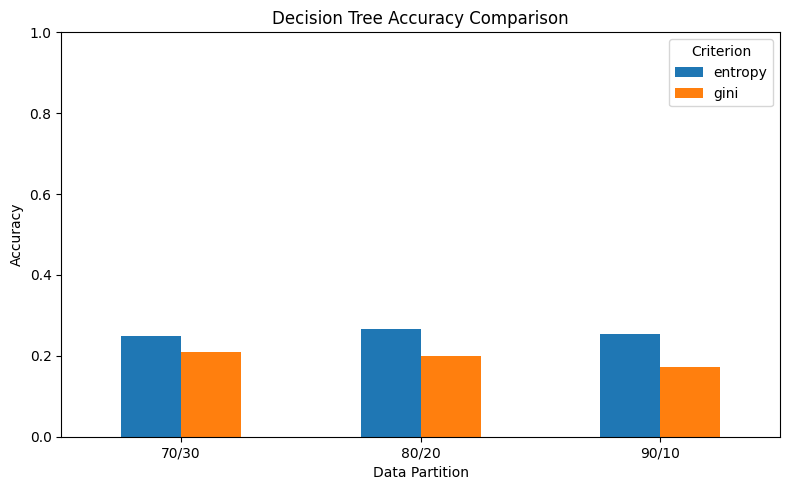

In [100]:

# Compare the accuracy of Gini and Entropy
accuracy_table = results_df.pivot(
    index="Partition",
    columns="Criterion",
    values="Accuracy"
)

accuracy_table = accuracy_table.reindex(
    ["70/30", "80/20", "90/10"]
)

accuracy_table.plot(kind="bar", figsize=(8, 5))

plt.title("Decision Tree Accuracy Comparison")
plt.xlabel("Data Partition")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Criterion")
plt.tight_layout()
plt.show()


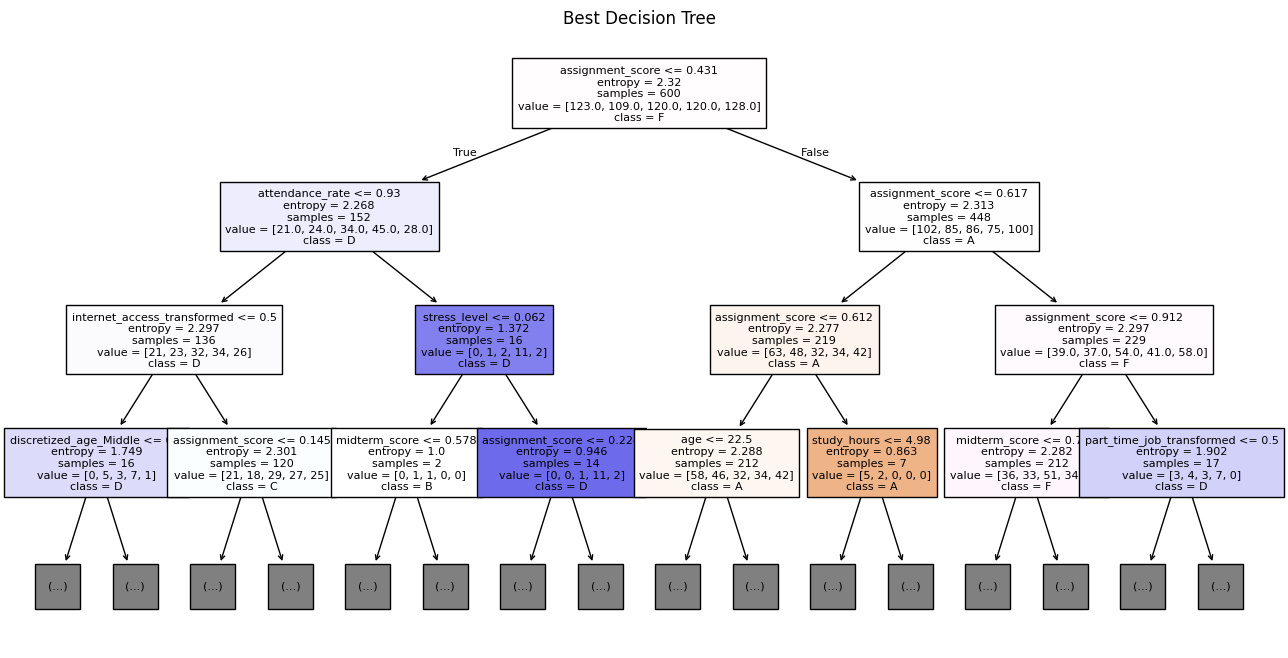

In [101]:

# Draw the tree to see how the model makes its decisions
plt.figure(figsize=(16, 8))

tree.plot_tree(
    best_clf,
    feature_names=fn,
    class_names=[str(c) for c in best_clf.classes_],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Best Decision Tree")
plt.show()


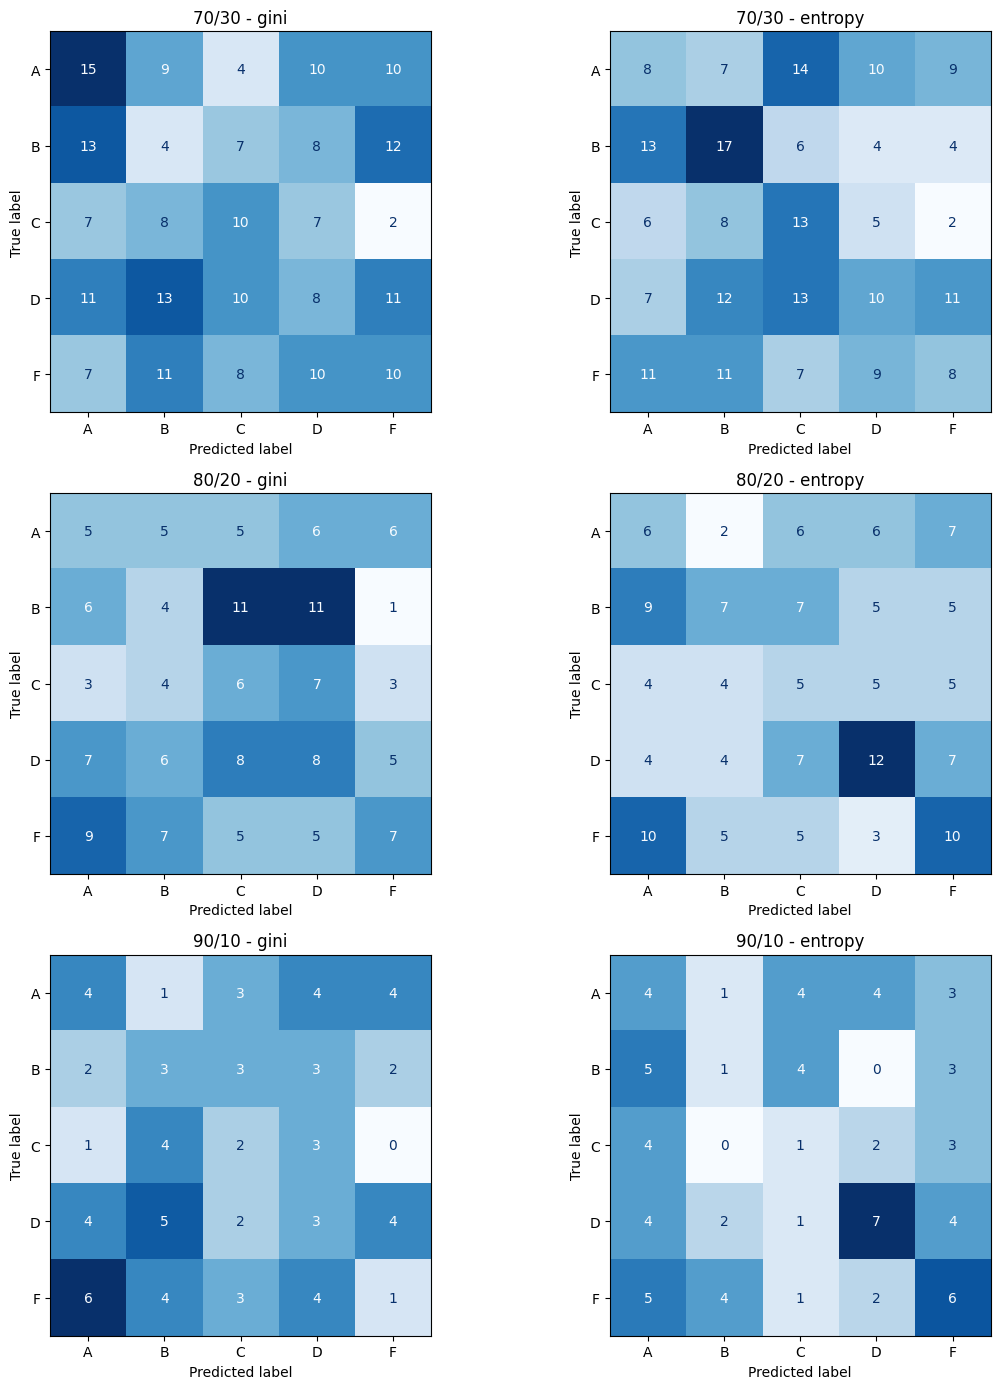

In [102]:

# Show the confusion matrix for all six experiments
fig, axes = plt.subplots(3, 2, figsize=(12, 14))

for ax, result in zip(axes.flat, result_matrices):

    disp = metrics.ConfusionMatrixDisplay(
        confusion_matrix=result["Matrix"],
        display_labels=result["Labels"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(
        result["Partition"] + " - " + result["Criterion"]
    )

plt.tight_layout()
plt.show()


**Description:** The table compares the performance of Decision Tree Classification using Gini and Entropy with three different data partitions (70/30, 80/20, and 90/10).

**What it tells us:** The results show differences in accuracy between Gini and Entropy across the three partitions. The training accuracy is also compared with the testing accuracy to check for overfitting.

**Conclusion:** The best-performing configuration is identified based on testing accuracy. However, the difference between training and testing accuracy should also be considered when evaluating the model.

# 2. Clustering

## 2.1 Preparing the Data for Clustering

In [103]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [104]:
# Load
df = pd.read_csv("Preprocessed_dataset.csv")

# Keep the class label aside
target = df["final_grade"]

# Remove the ID, the class label, and the text columns
# (the text columns already have numeric versions ending in _transformed)
# We also remove gender, because we want clusters based on student behaviour and performance
features = df.drop(columns=[
    "student_id",
    "final_grade",
    "final_grade_transformed",
    "gender",
    "gender_transformed",
    "internet_access",
    "parent_education",
    "part_time_job",
    "extracurricular",
    "discretized_age",
    "discretized_study_hours"
])

# Scale the features so no attribute dominates the distance
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)
SG_scaled = pd.DataFrame(scaled_features, columns=features.columns)

print("Features:", SG_scaled.columns.tolist())
print("Dataset shape:", SG_scaled.shape)
print("\nScaled DataFrame:")
print(SG_scaled.head())

Features: ['age', 'study_hours', 'attendance_rate', 'assignment_score', 'midterm_score', 'final_score', 'sleep_hours', 'stress_level', 'internet_access_transformed', 'part_time_job_transformed', 'extracurricular_transformed', 'parent_education_transformed']
Dataset shape: (750, 12)

Scaled DataFrame:
        age  study_hours  attendance_rate  assignment_score  midterm_score  \
0  1.522341    -0.615343        -0.838550          0.624783      -0.256269   
1  0.024629    -0.486913        -1.230996          0.085491      -2.939325   
2  0.523866     0.392834        -0.257149          1.228207      -0.072521   
3  1.522341    -0.384169         1.014238         -0.904668       1.199251   
4 -0.474608    -1.199701         0.302877         -0.200188       0.057633   

   final_score  sleep_hours  stress_level  internet_access_transformed  \
0     0.662191     0.437271     -1.198128                    -2.314289   
1     0.767515    -0.156688      0.366008                     0.432098   
2    -1

## 2.2 Choosing the Number of Clusters (k)

### 2.2.1 The emperical rule

In [105]:
# Empirical rule: k= the square root of n/2
n = len(SG_scaled)
empirical_k = np.sqrt(n / 2)

print("Number of objects (n):", n)
print("sqrt(n/2) =", round(empirical_k, 2))
print("Chosen k from the empirical rule:", round(empirical_k))

Number of objects (n): 750
sqrt(n/2) = 19.36
Chosen k from the empirical rule: 19


### 2.2.2 The Elbow method (WSS only)


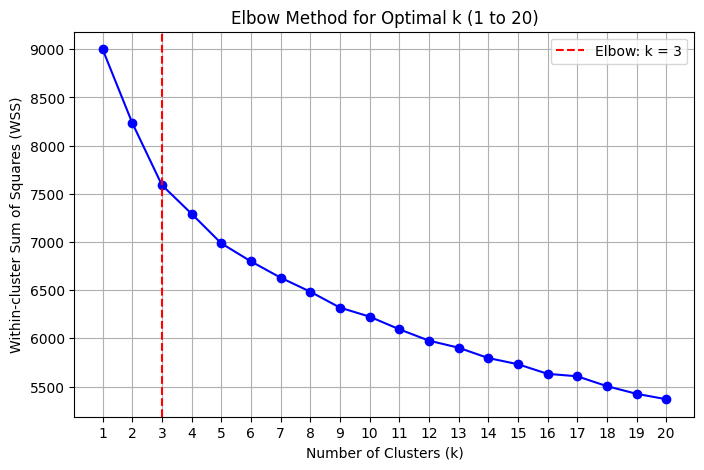

k = 1 -> 2: WSS drops by 764.6
k = 2 -> 3: WSS drops by 644.9
k = 3 -> 4: WSS drops by 297.6
k = 4 -> 5: WSS drops by 306.5
k = 5 -> 6: WSS drops by 187.5
k = 6 -> 7: WSS drops by 168.9
k = 7 -> 8: WSS drops by 145.6
k = 8 -> 9: WSS drops by 165.0
k = 9 -> 10: WSS drops by 93.7


In [106]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Elbow method: run k-means for k = 1 to 20 and record the WSS
k_values = list(range(1, 21))
wss_values = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=25)
    kmeans.fit(SG_scaled)
    wss_values.append(kmeans.inertia_)

# Plot the elbow curve (WSS only)
plt.figure(figsize=(8, 5))
plt.plot(k_values, wss_values, marker='o', linestyle='-', color='blue')
plt.axvline(x=3, linestyle='--', color='red', label='Elbow: k = 3')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-cluster Sum of Squares (WSS)')
plt.title('Elbow Method for Optimal k (1 to 20)')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

# Show how much the WSS drops each time we add a cluster
for i in range(1, 10):
    print(f"k = {k_values[i-1]} -> {k_values[i]}: WSS drops by {wss_values[i-1] - wss_values[i]:.1f}")

### 2.2.3 The Sihlouette method (average silhouette only)

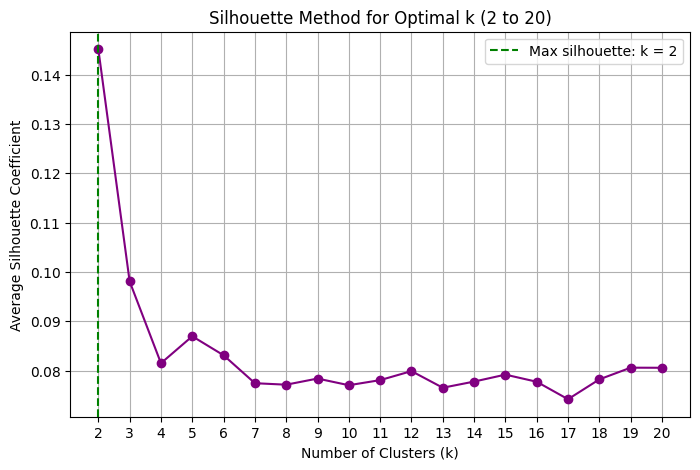

k = 2: average silhouette = 0.1452
k = 3: average silhouette = 0.0981
k = 4: average silhouette = 0.0815
k = 5: average silhouette = 0.0870
k = 6: average silhouette = 0.0831
k = 7: average silhouette = 0.0774
k = 8: average silhouette = 0.0771
k = 9: average silhouette = 0.0784
k = 10: average silhouette = 0.0770
k = 11: average silhouette = 0.0781
k = 12: average silhouette = 0.0799
k = 13: average silhouette = 0.0765
k = 14: average silhouette = 0.0778
k = 15: average silhouette = 0.0792
k = 16: average silhouette = 0.0777
k = 17: average silhouette = 0.0742
k = 18: average silhouette = 0.0782
k = 19: average silhouette = 0.0806
k = 20: average silhouette = 0.0806

Best k by silhouette: 2


In [107]:
from sklearn.metrics import silhouette_score

# Silhouette method: run k-means for k = 2 to 20 and record the average silhouette
sil_k_values = list(range(2, 21))
sil_values = []

for k in sil_k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=25)
    labels = kmeans.fit_predict(SG_scaled)
    sil_values.append(silhouette_score(SG_scaled, labels))

# Best k = the one that maximizes the average silhouette
best_k = sil_k_values[int(np.argmax(sil_values))]

# Plot the silhouette curve
plt.figure(figsize=(8, 5))
plt.plot(sil_k_values, sil_values, marker='o', linestyle='-', color='purple')
plt.axvline(x=best_k, linestyle='--', color='green',
            label=f'Max silhouette: k = {best_k}')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Coefficient')
plt.title('Silhouette Method for Optimal k (2 to 20)')
plt.xticks(sil_k_values)
plt.legend()
plt.grid(True)
plt.show()

# Print the values
for k, s in zip(sil_k_values, sil_values):
    print(f"k = {k}: average silhouette = {s:.4f}")
print(f"\nBest k by silhouette: {best_k}")

**Description:** We used three methods from the lecture to choose the number of clusters.
The empirical rule gives k = √(750/2) ≈ 19.36, so k = 19.
The elbow method plots the total within-cluster sum of squares (WSS) for k = 1 to 20.
The silhouette method gives the highest average silhouette at k = 2.

**What it tells us:** The WSS always decreases as k increases. The largest drops are from k = 1 to 2 (765) and from k = 2 to 3 (645). After k = 3 the drop is less than half as large (298), and the curve keeps declining gradually. So the elbow is at k = 3. The elbow is not very sharp, which suggests that the students do not form strongly separated groups.

**Conclusion:** We selected three values of k: **k = 19** (empirical rule), **k = 3** (elbow method), and **k = 2** (highest average silhouette).

## 2.3 K-Means Clustering

In [108]:
# Set a fixed seed so the results are the same every time
np.random.seed(42)

# This function runs k-means for a given k and prints the results
def run_kmeans(k):

    # Run k-means clustering with k clusters
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=25)
    kmeans_result = kmeans.fit(SG_scaled)

    # Print the clustering result
    print(f"===== k = {k} =====")

    print("\nCluster Centers:")
    print(pd.DataFrame(kmeans_result.cluster_centers_, columns=SG_scaled.columns).round(2))

    print("\nCluster Labels (first 20):")
    print(kmeans_result.labels_[:20])

    print("\nObjects per cluster:")
    print(pd.Series(kmeans_result.labels_).value_counts().sort_index())

    return kmeans_result

**by Empirical Rule**

In [109]:
# 1st call: k = 19 (by empirical rule)
kmeans_result_19= run_kmeans(19)

===== k = 19 =====

Cluster Centers:
     age  study_hours  attendance_rate  assignment_score  midterm_score  \
0   0.05        -0.73             0.99              0.64           0.58   
1   0.45         0.66            -0.15             -0.47           0.49   
2  -0.19         0.16            -0.52              0.45          -0.08   
3   0.70        -0.58            -0.10             -0.08          -1.23   
4   0.62         0.78            -0.91              0.79           0.01   
5  -0.50         0.17            -0.51             -0.00           0.21   
6   0.68         0.14             0.09             -0.90           0.02   
7  -0.05         0.02             0.03              0.75          -0.02   
8   0.22         0.05             0.13              0.13           0.10   
9  -0.82         0.04            -0.62             -0.30          -0.14   
10 -0.30        -0.22             0.60             -0.88          -0.01   
11 -0.26         0.06            -0.54              0.13       

**by elbow method**

In [110]:
# 2nd call: k = 3 (by elbow method)
kmeans_result_3= run_kmeans(3)

===== k = 3 =====

Cluster Centers:
    age  study_hours  attendance_rate  assignment_score  midterm_score  \
0  0.00        -0.03            -0.08              0.04          -0.11   
1 -0.05        -0.00             0.03             -0.10           0.08   
2  0.12         0.08             0.11              0.17           0.07   

   final_score  sleep_hours  stress_level  internet_access_transformed  \
0         0.01        -0.02         -0.02                         0.43   
1         0.04        -0.03          0.04                         0.43   
2        -0.13         0.13         -0.06                        -2.31   

   part_time_job_transformed  extracurricular_transformed  \
0                       0.04                         0.98   
1                      -0.03                        -1.02   
2                      -0.03                         0.02   

   parent_education_transformed  
0                          0.00  
1                          0.00  
2                      

**By highest silhouette avg**

In [111]:
# 3rd call: k = 2 (by highest silhouette)
kmeans_result_2= run_kmeans(2)

===== k = 2 =====

Cluster Centers:
    age  study_hours  attendance_rate  assignment_score  midterm_score  \
0  0.12         0.08             0.11              0.17           0.07   
1 -0.02        -0.02            -0.02             -0.03          -0.01   

   final_score  sleep_hours  stress_level  internet_access_transformed  \
0        -0.13         0.13         -0.06                        -2.31   
1         0.02        -0.02          0.01                         0.43   

   part_time_job_transformed  extracurricular_transformed  \
0                      -0.03                         0.02   
1                       0.00                        -0.00   

   parent_education_transformed  
0                         -0.02  
1                          0.00  

Cluster Labels (first 20):
[0 1 0 1 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1]

Objects per cluster:
0    118
1    632
Name: count, dtype: int64


**Description:** We applied k-means clustering with k = 19, k = 3, and k = 2, using the same settings for each run (random_state = 42, n_init = 25). For each k we the cluster centers, and the number of students in each cluster. We clustered on 12 attributes: we excluded gender, because it is a demographic attribute and we wanted clusters based on student behaviour and performance.

**What it tells us:**
- **k = 19:** The clusters are small (21 to 64 students each) and the centers show no clear pattern.
- **k = 3:** Cluster 2 (118 students) contains students without internet access (internet_access_transformed = −2.31). Clusters 0 and 1 split the remaining students by extracurricular activities (0.98 vs −1.02). The academic attributes are close to 0 in all clusters.
- **k = 2:** The data is split almost entirely by internet access: 118 students without access and 632 with access.

**Conclusion:** The clusters are mainly formed by the binary attributes (internet access and extracurricular activities), not by academic performance. The empirical rule over-estimates k for a dataset of this size. The comparison of the three values of k is in Section 2.4.

## 2.4 Evaluation


### 2.4.1 Using Elbow Method

In [112]:
# Elbow evaluation of the three chosen k values (2, 3, 19)
wss_2 = kmeans_result_2.inertia_
wss_3 = kmeans_result_3.inertia_
wss_19 = kmeans_result_19.inertia_
total_ss = wss_values[0]   # WSS at k = 1 = total variance of the data

elbow_table = pd.DataFrame({
    "k": [2, 3, 19],
    "WSS": [wss_2, wss_3, wss_19]
})
elbow_table["% reduction vs k = 1"] = 100 * (total_ss - elbow_table["WSS"]) / total_ss
print("WSS at k = 1:", round(total_ss, 1))
print(elbow_table.round(1).to_string(index=False))



WSS at k = 1: 9000.0
 k    WSS  % reduction vs k = 1
 2 8235.4                   8.5
 3 7590.5                  15.7
19 5424.9                  39.7


**Conclusion:** The WSS at k = 1 is 9000 (the total variance of the 750 scaled students). The WSS of the three chosen values is:

| k | WSS | % reduction vs k = 1 |
|---|---|---|
| 2 | 8235.4 | 8.5% |
| 3 | 7590.5 | 15.7% |
| 19 | 5424.9 | 39.7% |

- **k = 3** is the turning point of the curve. Going from k = 2 to k = 3 still reduces the WSS by 645, but after k = 3 the gain per extra cluster falls below 300.
- **k = 2** is slightly too small, because adding one more cluster still gives a large reduction in WSS (645).
- **k = 19** has the lowest WSS, but this is expected since the WSS always decreases when k increases. From k = 3 to k = 19, 16 extra clusters reduce the WSS by only 2165.6 (about 135 per cluster), so the gain is small compared with the number of clusters added.
- The elbow is not sharp: even with 19 clusters the WSS is only 39.7% lower than with one cluster, so the students do not form very compact groups.

According to the Elbow method, **k = 3 is the best choice** among the three values.


### 2.4.2 Using Silhouette Coefficient

**Clusters Visualization**

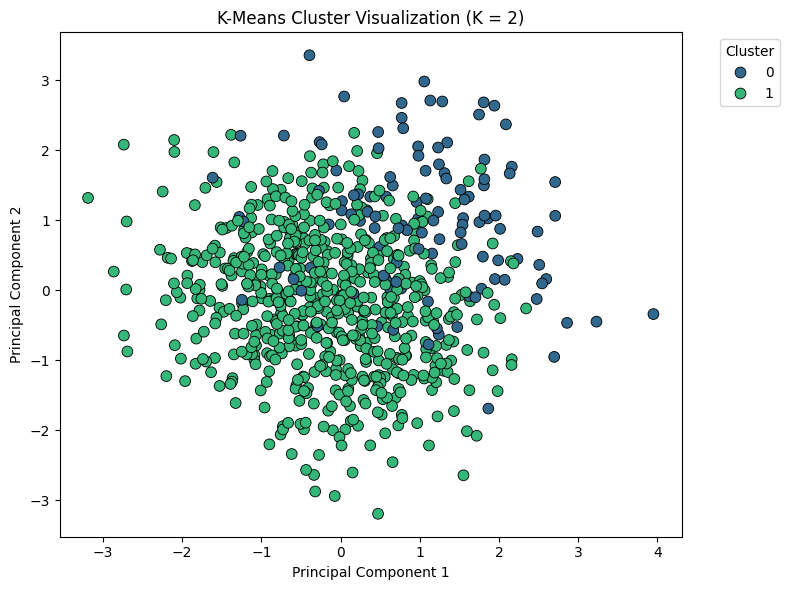

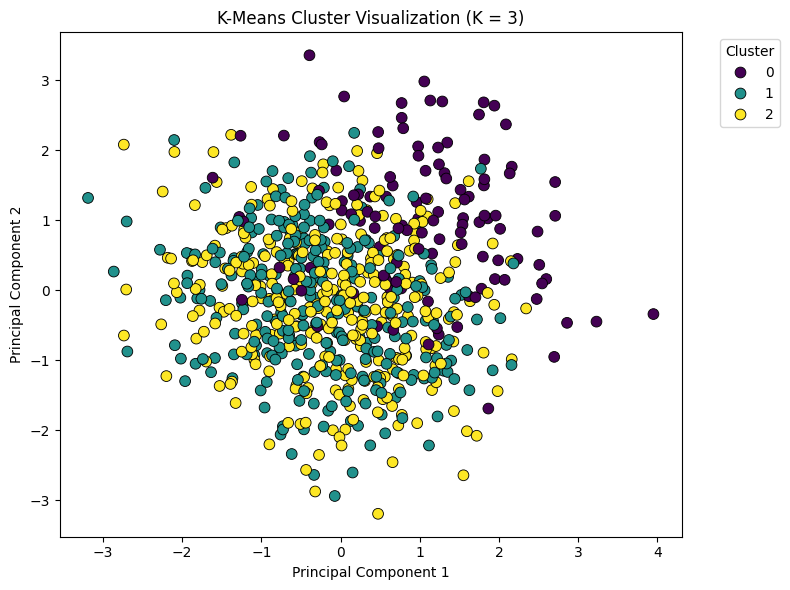

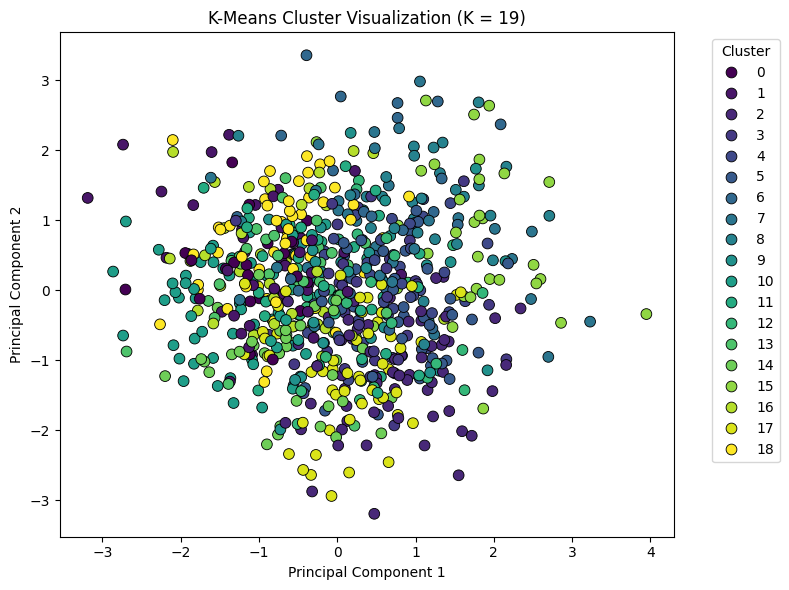

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import pandas as pd

# 1. Apply PCA to reduce the features down to 2 dimensions using your scaled DataFrame
pca = PCA(n_components=2, random_state=42)
principal_components = pca.fit_transform(SG_scaled)

# Create a DataFrame for the PCA results
pca_df = pd.DataFrame(
    data=principal_components,
    columns=['Principal Component 1', 'Principal Component 2']
)

# 2. Loop through each required value of K (2, 3, and 19)
k_values = [2, 3, 19]

for k in k_values:
    # Run k-means clustering with the current K
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(SG_scaled)

    # Assign cluster labels to the PCA DataFrame
    pca_df['Cluster'] = cluster_labels

    # 3. Visualize using a scatter plot colored by cluster label
    plt.figure(figsize=(8, 6))
    sns.scatterplot(
        x='Principal Component 1',
        y='Principal Component 2',
        hue='Cluster',
        data=pca_df,
        palette='viridis',
        edgecolor='k',
        s=60,
        legend='full'
    )
    plt.title(f'K-Means Cluster Visualization (K = {k})')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

**Silhouette Plots**

k = 2: average silhouette = 0.145
k = 3: average silhouette = 0.098
k = 19: average silhouette = 0.081


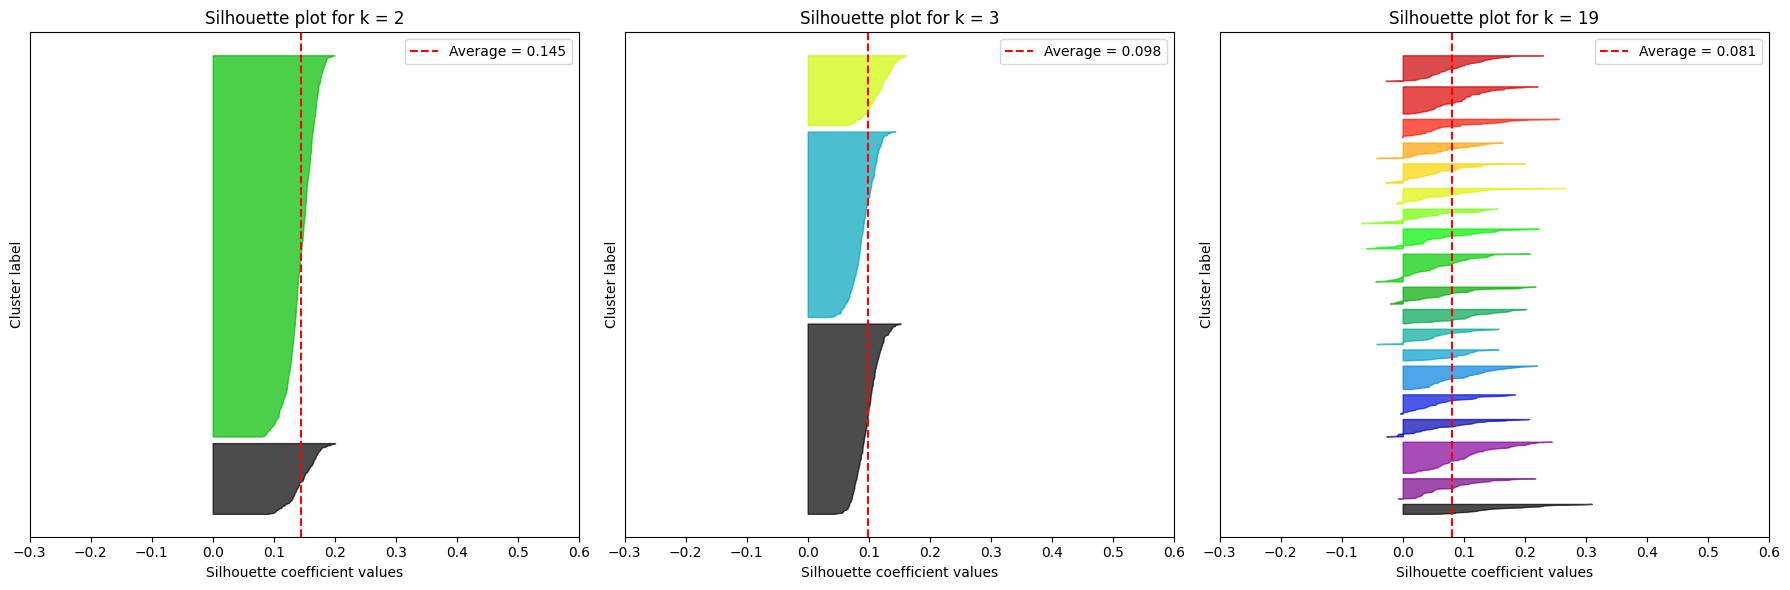

In [114]:
# Silhouette evaluation of the three chosen k values (2, 3, 19)
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

models = {2: kmeans_result_2, 3: kmeans_result_3, 19: kmeans_result_19}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (k, model) in zip(axes, models.items()):
    labels = model.labels_
    sample_sil = silhouette_samples(SG_scaled, labels)   # silhouette of every student
    avg_sil = sample_sil.mean()
    print(f"k = {k}: average silhouette = {avg_sil:.3f}")

    y_lower = 10
    for c in range(k):
        c_sil = np.sort(sample_sil[labels == c])
        y_upper = y_lower + len(c_sil)
        color = cm.nipy_spectral(c / k)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, c_sil,facecolor=color, edgecolor=color, alpha=0.7)
        y_lower = y_upper + 10

    ax.axvline(avg_sil, color='red', linestyle='--', label=f'Average = {avg_sil:.3f}')
    ax.set_xlim(-0.3, 0.6)
    ax.set_yticks([])
    ax.set_xlabel('Silhouette coefficient values')
    ax.set_ylabel('Cluster label')
    ax.set_title(f'Silhouette plot for k = {k}')
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


**Conclusion:** The silhouette coefficient measures how compact each cluster is and how well it is separated from the other clusters. Values close to 1 are preferable, and negative values mean that an object is closer to another cluster than to its own.

| k | Average silhouette |
|---|---|
| 2 | 0.145 |
| 3 | 0.098 |
| 19 | 0.081 |

- **k = 2** has the highest average silhouette of the three values (and of all values from 2 to 20).
- **k = 3** is lower, because the extra split divides the students with internet access by extracurricular activities only, so the two new clusters are close to each other.
- **k = 19** has the lowest value, because the 19 small clusters lie close to each other.
- All the values are low (the best is 0.145, far from 1), so the clusters are not strongly separated.

According to the silhouette coefficient, **k = 2 is the best choice** among the three values.


***Compare the results***

---



| k | Chosen by | WSS | Average silhouette | Cluster sizes |
|---|---|---|---|---|
| 2 | Highest silhouette | 8235.4 | **0.145** | 118 / 632 |
| 3 | Elbow method | 7590.5 | 0.098 | 118 / 312 / 320 |
| 19 | Empirical rule | **5424.9** | 0.081 | 21 to 64 |

- **Elbow method:** the WSS decreases as k increases, so k = 19 has the lowest WSS. The turning point of the curve is at k = 3, so k = 3 is the best of the three values.
- **Silhouette coefficient:** k = 2 has the highest average silhouette (0.145), and k = 19 the lowest (0.081), so k = 2 is the best of the three values.

**Agreement between the methods:**

 both methods reject k = 19. For k = 19 the WSS is lowest only because it has the largest number of clusters, and its silhouette is the lowest.
 The methods disagree between k = 2 and k = 3, because the Elbow method measures only compactness (and always rewards a larger k)while the silhouette measures compactness and separation together and penalizes the k = 3 split whose new clusters are close to each other.

**Interpretation:**

for k = 2, the students are split by internet access (118 without and 632 with).
For k = 3, the students with internet access are split further by extracurricular activities.
For k = 19, the clusters are small and show no clear pattern.
 In all cases the clusters are formed by these binary attributes and not by the academic attributes, and the low silhouette values show that the cluster structure is weak.

**Final conclusion:**

k = 19 (empirical rule) is not suitable for this dataset. k = 2 gives the best separation between clusters (highest silhouette), while k = 3 gives the best compactness-to-size balance (elbow).
We consider **k = 2** the best clustering because the silhouette coefficient evaluates both compactness and separation.
